# Stroke Risk Prediction - Phase 2: Refined Pipeline  Student: Priscilla Addai Asamoah | Date: 24th Jan 2026

In [1]:
%pip install --upgrade scikit-learn numpy
%pip install matplotlib
%pip install seaborn
%pip install plotly==5.22.0
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# 1. Exploratory Data Analysis (EDA)
## Goals: Visualize Outliers,skewness, and class imbalance to justify preprocessing steps.

In [2]:
#Loading ILPD dataset into pandas dataframe
df_ilpd = pd.read_csv('ILPD_data.csv')
df_ilpd.head()


,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.9,1
0,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
1,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
2,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
3,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
4,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1


In [3]:
#Adding the standard variable names from uci repository for merging in later step
ilpd_column_names = [
    'Age',
    'Gender', # Renaming Gender to sex for matching column names for concatenation in later steps
    'TB',
    'DB',
    'Alkphos',
    'Sgpt',
    'Sgot',
    'TP',  
    'ALB',  
    'A/G Ratio',
    'Selector' #Target to split data into two sets
]

# Assign the new names to DataFrame in memory
df_ilpd.columns = ilpd_column_names

print("ILPD columns successfully renamed in the DataFrame.")

ILPD columns successfully renamed in the DataFrame.


<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        582 non-null    int64  
 1   Gender     582 non-null    str    
 2   TB         582 non-null    float64
 3   DB         582 non-null    float64
 4   Alkphos    582 non-null    int64  
 5   Sgpt       582 non-null    int64  
 6   Sgot       582 non-null    int64  
 7   TP         582 non-null    float64
 8   ALB        582 non-null    float64
 9   A/G Ratio  578 non-null    float64
 10  Selector   582 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.1 KB
None


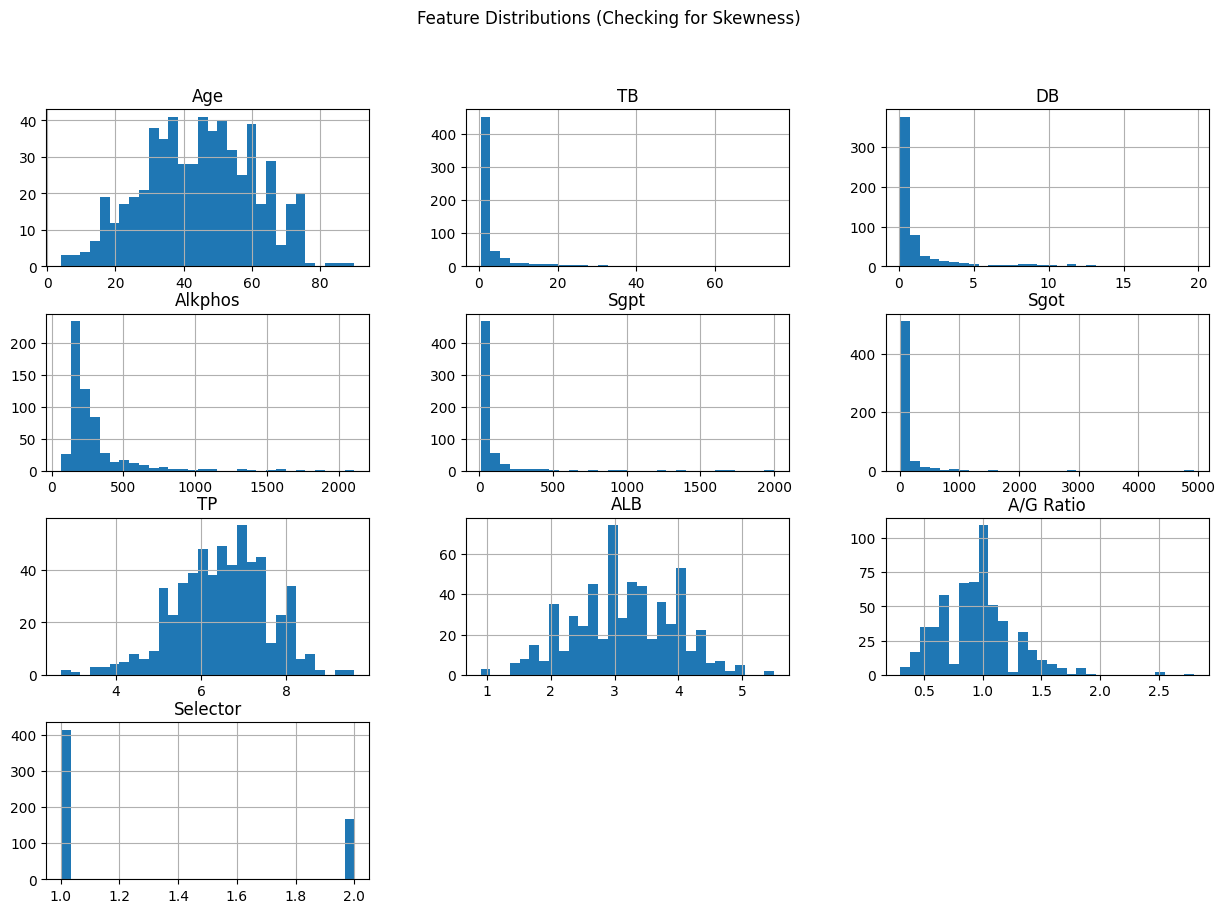

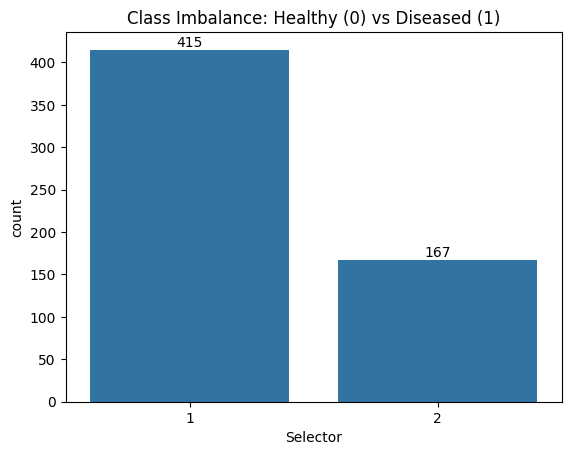

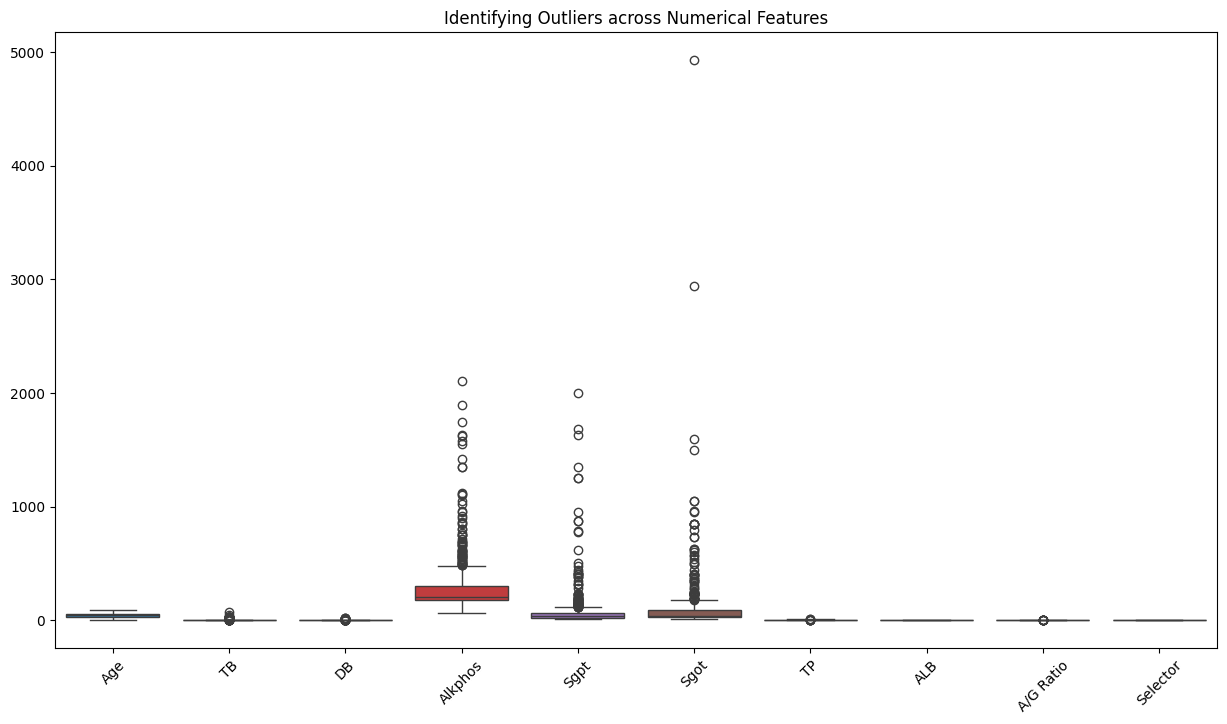

In [4]:
# 1. Show the numbers (Nulls and Types)
print(df_ilpd.info())

# 2. Visualize Skewness and Distributions (Histograms)
df_ilpd.hist(bins=30, figsize=(15, 10))
plt.suptitle("Feature Distributions (Checking for Skewness)")
plt.show()

# 3. Visualize the Class Imbalance (The Target)
ax = sns.countplot(x='Selector', data=df_ilpd)
plt.title("Class Imbalance: Healthy (0) vs Diseased (1)") # Visualisation is showing 1 and 2 because this is before mapping the labels correctly to 0 and 1 
for label in ax.containers:
    ax.bar_label(label)#adding number values to bar objects 
plt.show()

# 4. Visualize Outliers (Boxplots)
plt.figure(figsize=(15, 8))
sns.boxplot(data=df_ilpd.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.title("Identifying Outliers across Numerical Features")
plt.show()

### Analysis for Histograms,Boxplots and Countplot
The histograms show that TB,DB,Alkphos,sgpt and Sgot are heavily right skewed showing a majority with low levels and a small group with extremely high levels justifying the use of median imputation despite oversimplification, which provides a more accurate representation of the values without being affected by outliers as opposed to mean imputation which gets pulled by the tail.

The boxplots show that there are extreme outliers for example features such as Alkphos,Sgpt, and Sgot. reaching above 4000 which can affect the model's performance and interpretability as well as statistical validity and create an impact on analysis. This justifies the use of IQR removal method which i will later be using.

The countplots show the difference in balance between the healthy patients (2) and unhealthy patients (1). The 1 and 2 being encoded like that demonstrates the messiness of the target labels from the standard 0 and 1. The plot shows that the the data has more unhealthy patients (415) and less healthy patients (167) in the dataset which shows why i later use SMOTE to balance things.

# 2. Data Preprocessing & Transformation
## Steps: Median Imputation, IQR Outlier Removal, and Categorical Encoding

In [5]:
df_ilpd.info()
print(df_ilpd.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        582 non-null    int64  
 1   Gender     582 non-null    str    
 2   TB         582 non-null    float64
 3   DB         582 non-null    float64
 4   Alkphos    582 non-null    int64  
 5   Sgpt       582 non-null    int64  
 6   Sgot       582 non-null    int64  
 7   TP         582 non-null    float64
 8   ALB        582 non-null    float64
 9   A/G Ratio  578 non-null    float64
 10  Selector   582 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.1 KB
Age          0
Gender       0
TB           0
DB           0
Alkphos      0
Sgpt         0
Sgot         0
TP           0
ALB          0
A/G Ratio    4
Selector     0
dtype: int64


In [6]:


# Calculating the skewness of  column 9 to determine how asymmetrical the data is to choose between a median or mean imputation 
skewness_value = skew(df_ilpd['A/G Ratio'].dropna())

print(f"Skewness of Columns: {skewness_value}")

Skewness of Columns: 0.9881687411239792


In [7]:
#Using median imputation for the column 9 with 4 missing values
from sklearn.impute import SimpleImputer


num_cols = df_ilpd.select_dtypes(include='float64').columns
num_imputer = SimpleImputer(strategy='median')
df_ilpd[num_cols] = num_imputer.fit_transform(df_ilpd[num_cols])

In [8]:
#Checking cleaning has been completed
df_ilpd_cleaned = df_ilpd.copy()

df_ilpd_cleaned.info()
print(df_ilpd_cleaned.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        582 non-null    int64  
 1   Gender     582 non-null    str    
 2   TB         582 non-null    float64
 3   DB         582 non-null    float64
 4   Alkphos    582 non-null    int64  
 5   Sgpt       582 non-null    int64  
 6   Sgot       582 non-null    int64  
 7   TP         582 non-null    float64
 8   ALB        582 non-null    float64
 9   A/G Ratio  582 non-null    float64
 10  Selector   582 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.1 KB
Age          0
Gender       0
TB           0
DB           0
Alkphos      0
Sgpt         0
Sgot         0
TP           0
ALB          0
A/G Ratio    0
Selector     0
dtype: int64


In [9]:
print(df_ilpd.columns)

Index(['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB',
       'A/G Ratio', 'Selector'],
      dtype='str')


In [10]:
import pandas as pd
### Outlier Diagnosis: Identifying Extreme Clinical Values ###
# Select only the numerical columns
numerical_cols = ['Age', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio']

# Create a function to find outliers using IQR
def find_outliers(df_ilpd, column):
    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = df_ilpd[column].quantile(0.25)
    Q3 = df_ilpd[column].quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Define the lower and upper bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Find outliers
    outliers = df_ilpd[(df_ilpd[column] < lower_bound) | (df_ilpd[column] > upper_bound)]
    return outliers

# Check for outliers in each numerical column
for col in numerical_cols:
    outliers = find_outliers(df_ilpd, col)
    print(f"\nOutliers in '{col}':")
    print(outliers[[col]])



Outliers in 'Age':
Empty DataFrame
Columns: [Age]
Index: []

Outliers in 'TB':
       TB
0    10.9
1     7.3
21    6.8
26    6.2
36   14.2
..    ...
571  15.6
573  12.1
574  25.0
575  15.0
576  12.7

[84 rows x 1 columns]

Outliers in 'DB':
       DB
0     5.5
1     4.1
21    3.0
26    3.0
36    7.8
..    ...
571   9.5
573   6.0
574  13.7
575   8.2
576   8.4

[81 rows x 1 columns]

Outliers in 'Alkphos':
     Alkphos
0        699
1        490
19       610
21       542
41       630
..       ...
548      768
572      612
573      515
574      560
577      500

[66 rows x 1 columns]

Outliers in 'Sgpt':
     Sgpt
15    168
17    232
18    232
24    875
25    875
..    ...
559   321
560   233
561   173
568   213
569   131

[73 rows x 1 columns]

Outliers in 'Sgot':
     Sgot
15    441
17    245
18    245
24    731
25    731
..    ...
547   186
557   330
559   562
560   384
561   367

[66 rows x 1 columns]

Outliers in 'TP':
      TP
179  2.7
180  3.0
268  2.8
269  9.5
272  9.6
414  3.6
45

# Analysis of Outliers 

In [11]:
# Collect indices of all outliers
outlier_indices = set()
for col in numerical_cols:
    outliers = find_outliers(df_ilpd, col)
    outlier_indices.update(outliers.index)

# Drop the outlier rows
df_clean = df_ilpd.drop(outlier_indices)
# Show the shape of the original and cleaned DataFrames
print("Original DataFrame shape:", df_ilpd.shape)
print("Cleaned DataFrame shape:", df_clean.shape)


Original DataFrame shape: (582, 11)
Cleaned DataFrame shape: (400, 11)


In [12]:
from sklearn.preprocessing import OneHotEncoder
df_final = df_clean.copy() #Here i made a safety copy to avoid re-runnign the wholw notebook
#changing df_clean.copy() for refined data shape of 582 patients
# Remapping Target to 0/1
if 2 in df_final['Selector'].unique():
    df_final['Selector'] = df_final['Selector'].map({2: 0, 1: 1}) # The original ILPD data mapped 1  and 2 to patients. Models use 0 and 1 for confusion matrix and recall scores

##--------------------------------------ENCODING--------------------------------##
# Handling Gender using Scikit-learn onehotencoding as Gender has no natural 'rank' or level
# This correctly creates numerical columns for gender as computers only work with numbers
cat_encoder = OneHotEncoder(drop='first', sparse_output=False)#sparce output to ensure it returns a table we can see and drop column to only make 1 columns gender_male and drops female 
gender_encoded = cat_encoder.fit_transform(df_final[['Gender']])#encoder requires [] for 2d array

# Add it back to the dataframe
df_final['Gender_Male'] = gender_encoded # 0 means not male 1 means male 
df_final.drop('Gender', axis=1, inplace=True)

# Double-check the columns after 
print("Columns after oneHotEncoding:", df_final.columns) # Make sure 'Gender_Male' (or similar) is here


Columns after oneHotEncoding: Index(['Age', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio',
       'Selector', 'Gender_Male'],
      dtype='str')


In [13]:
#Checking for class imbalance
X = df_final.drop(['Selector'], axis=1)
y = df_final['Selector']

y.value_counts()

Selector
1    247
0    153
Name: count, dtype: int64

<Axes: >

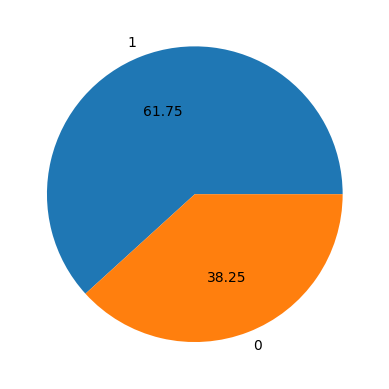

In [14]:
    #Show pie plot of imbalance
y.value_counts().plot.pie(autopct='%.2f')

In [15]:
print(X.dtypes)


Age              int64
TB             float64
DB             float64
Alkphos          int64
Sgpt             int64
Sgot             int64
TP             float64
ALB            float64
A/G Ratio      float64
Gender_Male    float64
dtype: object


# 3. Feature Selection
## Goals: improve accuracy and clinical relevace , remove multicollinearity and noise using Correlation Heatmaps and RFE for the baseline model 

Following the architecture in Géron's 'Hands-On ML' (Chapter 2), I have moved the visualization and feature selection phases to the start of the pipeline to ensure a data-driven approach to modeling.

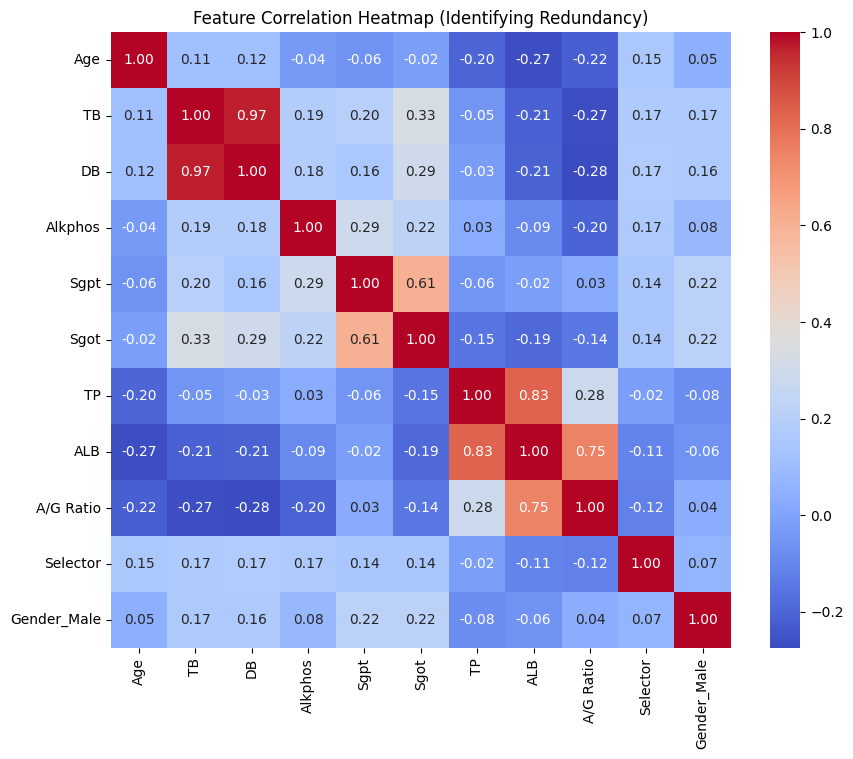

In [16]:
#Doing feature selection so that the 8 most important features are found using the simplest , baseline model first 
#1. Calculating correlations 
corr_matrx = df_final.corr()

#2. Drawing the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrx, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Heatmap (Identifying Redundancy)")
plt.show()

### Critical Analysis of Feature Correlations:
Redundancy identified (Multicollinearity): A near-perfect correlation of 0.97 was found between TB and DB. Following clinical logic (where DB is a subset of TB), I will remove DB to reduce noise.
High Correlation detected: TP and ALB show a correlation of 0.83. To ensure the model remains transparent and focuses on specific clinical markers, I will prioritize ALB and investigate dropping TP. A/G Ratio and ALB also show a high correlation of 0.75, I will prioritise dropping
Weak Predictor Analysis: Both Gender_Male (0.07) and TP (-0.02) show negligible correlation with the target variable (Selector). These will be primary candidates for removal during the Recursive Feature Elimination (RFE) phase to improve model generalizability.

In [3]:
# Checking correlation data
print("TB correlation with target:", corr_matrx['Selector']['TB'])
print("DB correlation with target:", corr_matrx['Selector']['DB'])

print("A/G Ratio correlation with target:", corr_matrx['Selector']['A/G Ratio'])
print("ALB correlation with target:", corr_matrx['Selector']['ALB'])

NameError: name 'corr_matrx' is not defined

# Retaining Features
Although DB showed marginally higher correlation with the target (r=0.173) compared to TB (r=0.169), I retained TB and A/G Ratio because it represents the complete bilirubin profile (TB = DB + Indirect Bilirubin abd A/G Ratio represents both Albumin and Globulin asopposed to ALB which just represent Albumin), providing richer clinical information. The 0.004 difference in correlation is negligible compared to the interpretability advantage of using the standard clinical marker and A/G Ratio has a stronger correlation than ALB

In [18]:
#Dropping 3 features leaving us with 7 unique clincal signals 
X = df_final.drop(['Selector', 'DB', 'ALB', 'TP'], axis=1)
y = df_final['Selector']

# 4. Comparitive Model Building 
## Task: Comparing Baseline Logistic Regression vs Refined Model

In [19]:
#---------------------------MODELING  INTERNALLY---------------------------------# 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as lr
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
#Split data into training and testing
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.4,random_state=42)
print('Length of training and testing data is: ')
print('X_train=%.3f, X_test=%.3f, y_train=%3f, y_test=%.3f' % (len(X_train),len(X_test),len(y_train),len(y_test)))

Length of training and testing data is: 
X_train=240.000, X_test=160.000, y_train=240.000000, y_test=160.000


In [20]:
#SMOTE Oversampling method used to reduce majority to balance with minority 
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42, sampling_strategy='auto')
X_train_res, y_train_res = sm.fit_resample(X_train,y_train)

print("Data split and balanced ready for RFE")


Data split and balanced ready for RFE


<Axes: >

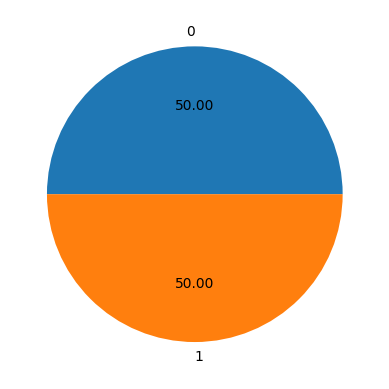

In [21]:
#Show pie plot of balance
y_train_res.value_counts().plot.pie(autopct='%.2f')

In [22]:
print("Original X shape:", X.shape)
print("Resampled X shape:", X_train_res.shape)
print("Original y shape:", y.shape)
print("Resampled y shape:", y_train_res.shape)


Original X shape: (400, 7)
Resampled X shape: (284, 7)
Original y shape: (400,)
Resampled y shape: (284,)


# Recursive feature elimination(RFE)

In [23]:
#While pearson correlation identified the redundancies between the features and the signals close to 0. rfe will identify any signals and feature interactions
from sklearn.feature_selection import RFE
from sklearn.metrics import f1_score

rfe_f1_score_list = []
#Looping from 1 to 7 because we have 7 features left after manual drops
for k in range(1, 8):
       #Using logistic regression as the judge 
       RFE_selector = RFE(estimator=lr(max_iter=1000), n_features_to_select=k, step=1)
       RFE_selector.fit(X_train_res, y_train_res)
       #Transforming both train and test to the top k features
       sel_X_train = RFE_selector.transform(X_train_res)
       sel_X_test = RFE_selector.transform(X_test)
       #Creating logistic regression model instance
       tester_model = lr(max_iter=1000)
       tester_model.fit(sel_X_train, y_train_res)
       #Predict on test set (final exam)
       RFE_preds = tester_model.predict(sel_X_test)

       f1_score_rfe = round(f1_score(y_test, RFE_preds, average='weighted'), 3)

       rfe_f1_score_list.append(f1_score_rfe)

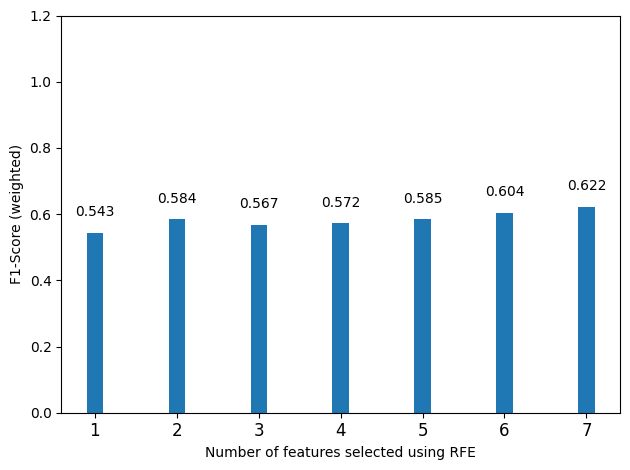

In [24]:
fig, ax = plt.subplots()

x = np.arange(1, 8)
y = rfe_f1_score_list

ax.bar(x, y, width=0.2)
ax.set_xlabel('Number of features selected using RFE' )
ax.set_ylabel('F1-Score (weighted)')
ax.set_ylim(0, 1.2)
ax.set_xticks(np.arange(1, 8))
ax.set_xticklabels(np.arange(1, 8), fontsize=12)

for i, v in enumerate(y):
  plt.text(x=i+1, y=v+0.05, s=str(v), ha='center')

plt.tight_layout()

In [25]:

# asking X_train for its column names, only the ones where selector said 'True'
rfe_winning_names = X_train.columns[RFE_selector.support_]

# This will print the list of names so you can see them
print("The selected clinical markers are:")
print(rfe_winning_names.tolist())


The selected clinical markers are:
['Age', 'TB', 'Alkphos', 'Sgpt', 'Sgot', 'A/G Ratio', 'Gender_Male']


# F-1 Score plot Analysis
The plot shows an features increasing at 7. The highest score is at 7 features(0.622) whilst 1-5 features' f1-scores are too simple and the model is guessing poorly.
A limitation of RFE is that it is prone to overfitting to this specific test set without cross validation. To ensure clinical validity I will implement below RFECV as suggested by Geeksforgeeks' blog 'Recursive Feature Elimination'.

In [26]:
from sklearn.feature_selection import RFECV

#Create the Logistic regression model instance
estimator = lr(max_iter=1000)

selector = RFECV(estimator, cv=5, step=1)
selector = selector.fit(X_train_res, y_train_res)

# Print the optimal number of features
print("Optimal number of features: %d" % selector.n_features_)

# Print the selected features
print("Selected features: %s" % selector.support_)


Optimal number of features: 7
Selected features: [ True  True  True  True  True  True  True]


In [27]:

# asking X_train for its column names, only the ones where selector said 'True'
rfecv_winning_names = X_train.columns[selector.support_]

# This will print the list of names so you can see them
print("The selected clinical markers are:")
print(rfecv_winning_names.tolist())


The selected clinical markers are:
['Age', 'TB', 'Alkphos', 'Sgpt', 'Sgot', 'A/G Ratio', 'Gender_Male']


In [28]:
from sklearn.pipeline import make_pipeline
#----------------------------MODELING INTENAL WEIGHT LR-------------------------------#
# Building the model on training data scaling the data to prevent data leakage instead of manually scaling it in the dataframe 

internal_balanced_pipe = make_pipeline(StandardScaler(), lr(class_weight='balanced', max_iter=1000))
internal_balanced_pipe.fit(X_train,y_train)

#Modeling the accuracy on test data
print("Model Accuracy on Testing Data: ", internal_balanced_pipe.score(X_test,y_test))


Model Accuracy on Testing Data:  0.5875


In [29]:
#Predictions on the test data mapped correctly to 1 and 0
internal_balanced_pipe.predict(X_test)

array([1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0])

In [30]:
#Probabilities that whether the person has chances of stroke or not on testing data
internal_balanced_pipe.predict_proba(X_test)

array([[0.45989351, 0.54010649],
       [0.43711543, 0.56288457],
       [0.71488331, 0.28511669],
       [0.72328757, 0.27671243],
       [0.21648062, 0.78351938],
       [0.46916947, 0.53083053],
       [0.73931829, 0.26068171],
       [0.28035806, 0.71964194],
       [0.61956888, 0.38043112],
       [0.60169634, 0.39830366],
       [0.18791243, 0.81208757],
       [0.33514141, 0.66485859],
       [0.64133082, 0.35866918],
       [0.71461298, 0.28538702],
       [0.49059173, 0.50940827],
       [0.43989065, 0.56010935],
       [0.50862406, 0.49137594],
       [0.23476337, 0.76523663],
       [0.05270221, 0.94729779],
       [0.41301433, 0.58698567],
       [0.51582661, 0.48417339],
       [0.49732598, 0.50267402],
       [0.26550077, 0.73449923],
       [0.55922589, 0.44077411],
       [0.54390739, 0.45609261],
       [0.66604837, 0.33395163],
       [0.61548419, 0.38451581],
       [0.72940442, 0.27059558],
       [0.43961299, 0.56038701],
       [0.16925208, 0.83074792],
       [0.

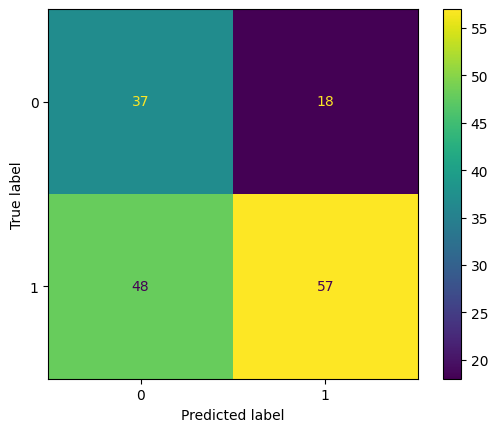

In [31]:
#Confusion Matrix
y_pred = internal_balanced_pipe.predict(X_test)
confusion_matrix(y_test,y_pred)

ConfusionMatrixDisplay.from_estimator(internal_balanced_pipe,X_test,y_test)


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

  No Disease       0.44      0.67      0.53        55
     Disease       0.76      0.54      0.63       105

    accuracy                           0.59       160
   macro avg       0.60      0.61      0.58       160
weighted avg       0.65      0.59      0.60       160



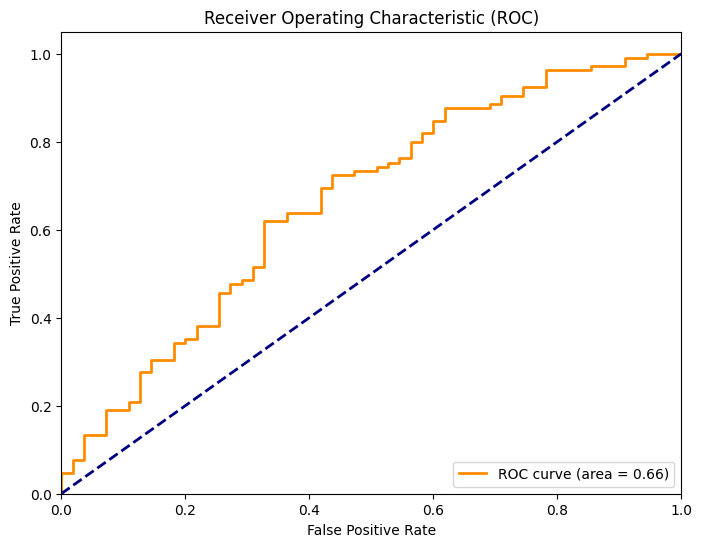

In [32]:
from sklearn.metrics import classification_report, roc_curve, auc
import matplotlib.pyplot as plt

# 1. Get the detailed scores (Precision, Recall, F1)
# We use the pipeline you already built
y_pred = internal_balanced_pipe.predict(X_test)
print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=['No Disease', 'Disease']))

# 2. Get the Probabilities for ROC Curve
# The model needs to guess the % chance, not just Yes/No
y_pred_proba = internal_balanced_pipe.predict_proba(X_test)[:, 1]

# 3. Calculate ROC Metrics
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# 4. Plot the Curve (Simple Matplotlib version - less likely to crash than Plotly)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

Model Accuracy on Testing Data:  0.5875
--- MODEL 2: SMOTE RESULTS ---
              precision    recall  f1-score   support

           0       0.44      0.67      0.53        55
           1       0.76      0.54      0.63       105

    accuracy                           0.59       160
   macro avg       0.60      0.61      0.58       160
weighted avg       0.65      0.59      0.60       160



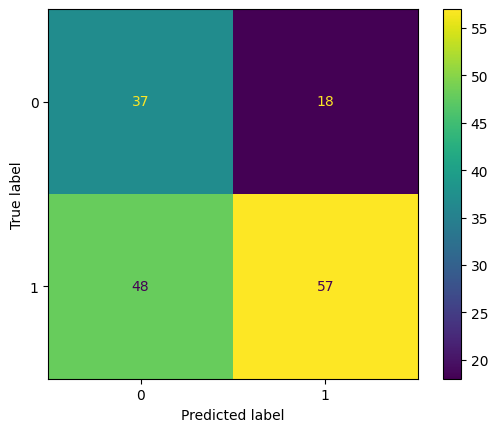

In [33]:
#-----------------------------------MODELING USING SMOTE -----------------------#
smote_pipe = make_pipeline(StandardScaler(), lr(max_iter=1000))
smote_pipe.fit(X_train_res, y_train_res)

y_pred_smote = smote_pipe.predict(X_test)

#Modeling the accuracy on test data
print("Model Accuracy on Testing Data: ", smote_pipe.score(X_test,y_test))

print("--- MODEL 2: SMOTE RESULTS ---")
print(classification_report(y_test, y_pred_smote))

ConfusionMatrixDisplay.from_estimator(smote_pipe,X_test, y_test)
plt.show()

Model Accuracy on Testing Data:  0.65
---MODEL 3: PURE IMBALANCED RESULTS ---
              precision    recall  f1-score   support

           0       0.49      0.44      0.46        55
           1       0.72      0.76      0.74       105

    accuracy                           0.65       160
   macro avg       0.61      0.60      0.60       160
weighted avg       0.64      0.65      0.64       160



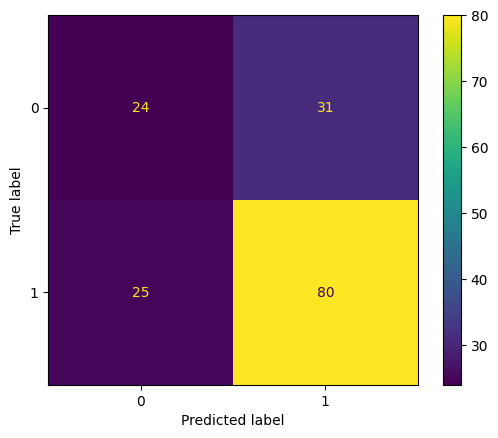

In [34]:
#-----------------------------------MODELING PURE -----------------------#
pure_pipe = make_pipeline(StandardScaler(), lr(max_iter=1000))
pure_pipe.fit(X_train,y_train)

y_pred_pure = pure_pipe.predict(X_test)
#Modeling the accuracy on test data
print("Model Accuracy on Testing Data: ", pure_pipe.score(X_test,y_test))

print("---MODEL 3: PURE IMBALANCED RESULTS ---")
print(classification_report(y_test, y_pred_pure))

ConfusionMatrixDisplay.from_estimator(pure_pipe,X_test, y_test)
plt.show()

# Evaluating the 3 models 
The goal of this experiment was to find the best model for handling the imbalanced class, priotising the detection of diseased patients recall.

After comparing the 3 models, the pure model seems to have better performance with True positives of 80, an accuracy of 0.65 and recall of 0.76  and with the 7 features selected contributing to this optimization and outperforming both SMOTE and the weighted versions. The comparison table below shows the differences in the 3 versions:

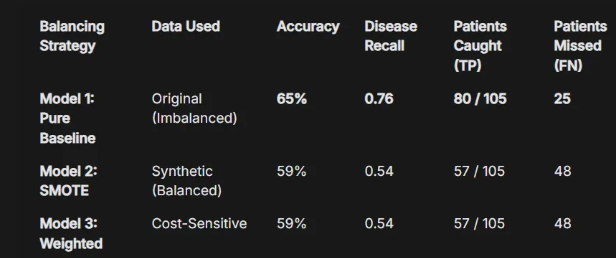

SMOTE and weighting both had a lower recall of 0.54, missing 48 sick patients whilst the pure model achived a recall of 0.76, correctly identifying 23 additional patients. The result shows that for the ILPD dataset, feature engineering was more improtant than class balancing. The synthetic data or  weights seems to have introduced a bias or noise that hindered the LR's prediction on the minority class.

Moving forward, ill train all three models on pure data first to be consistent with my best LR baseline and then if any model performs poorly I will investigate whether SMOTE would help that specific model

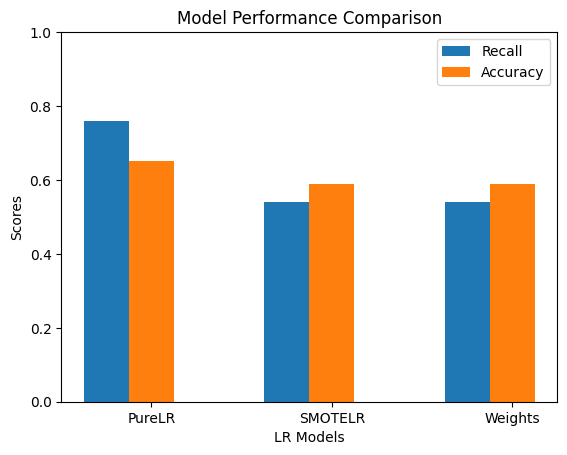

In [35]:

LR_models = ['PureLR', 'SMOTELR', 'Weights']
recall_scores = [0.76, 0.54, 0.54]
accuracy_scores = [0.65, 0.59, 0.59]



#set bar position
x = np.arange(len(LR_models))  # [0, 1, 2, 3]
width = 0.25  # width of each bar

# Create the bars
plt.bar(x - width, recall_scores, width, label='Recall')
plt.bar(x, accuracy_scores, width, label='Accuracy')


plt.xlabel('LR Models')
plt.ylabel('Scores')
plt.title('Model Performance Comparison')
plt.xticks(x, LR_models)  # Put model names on x-axis
plt.legend()
plt.ylim(0, 1)  # Scores range from 0 to 1
plt.show()

# 5. Training Remaining Models

## Random Forest Model

Model Accuracy on Testing Data:  0.64375
---CLASSIFICATION RESULTS ---
              precision    recall  f1-score   support

           0       0.48      0.44      0.46        55
           1       0.72      0.75      0.73       105

    accuracy                           0.64       160
   macro avg       0.60      0.59      0.60       160
weighted avg       0.64      0.64      0.64       160



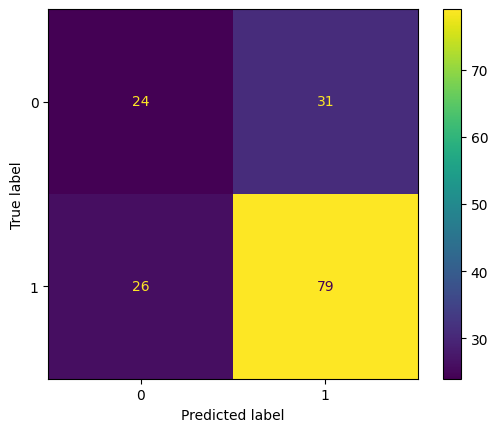

In [36]:
from sklearn.ensemble import RandomForestClassifier

#Skipping standardScaler as RF is a decision tree based model 
RF_pure_pipe = RandomForestClassifier(random_state=42, n_estimators=100)#common defualt trees of 100 
RF_pure_pipe.fit(X_train, y_train)
y_pred_RF = RF_pure_pipe.predict(X_test)
#Modeling the accuracy on test data
print("Model Accuracy on Testing Data: ", RF_pure_pipe.score(X_test,y_test))
print("---CLASSIFICATION RESULTS ---")
print(classification_report(y_test, y_pred_RF))

ConfusionMatrixDisplay.from_estimator(RF_pure_pipe,X_test, y_test)
plt.show()

# Support Vector Machines Model

Model Accuracy on Testing Data:  0.71875
---CLASSIFICATION RESULTS ---
              precision    recall  f1-score   support

           0       0.69      0.33      0.44        55
           1       0.72      0.92      0.81       105

    accuracy                           0.72       160
   macro avg       0.71      0.63      0.63       160
weighted avg       0.71      0.72      0.69       160



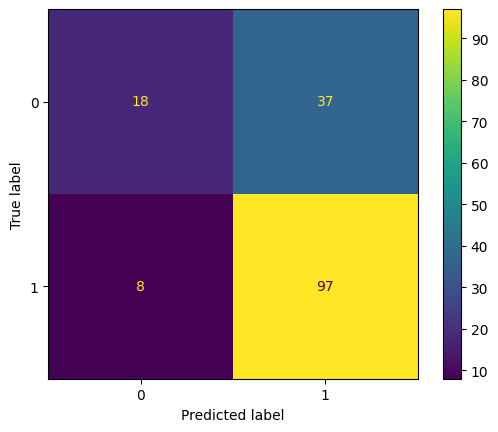

In [37]:
from sklearn.svm import SVC
#Using standardScaling because SVM uses distances 
svm_pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42, probability=True)) #we use default rbf to handle both linear and non-linear cases just incase 
svm_pipe.fit(X_train, y_train)
y_pred_svm = svm_pipe.predict(X_test)
#Modeling the accuracy on test data
print("Model Accuracy on Testing Data: ", svm_pipe.score(X_test,y_test))
print("---CLASSIFICATION RESULTS ---")
print(classification_report(y_test, y_pred_svm))

ConfusionMatrixDisplay.from_estimator(svm_pipe,X_test, y_test)
plt.show()

# Naive Bayes Model

Model Accuracy on Testing Data:  0.58125
---CLASSIFICATION RESULTS ---
              precision    recall  f1-score   support

           0       0.43      0.65      0.52        55
           1       0.75      0.54      0.63       105

    accuracy                           0.58       160
   macro avg       0.59      0.60      0.57       160
weighted avg       0.64      0.58      0.59       160



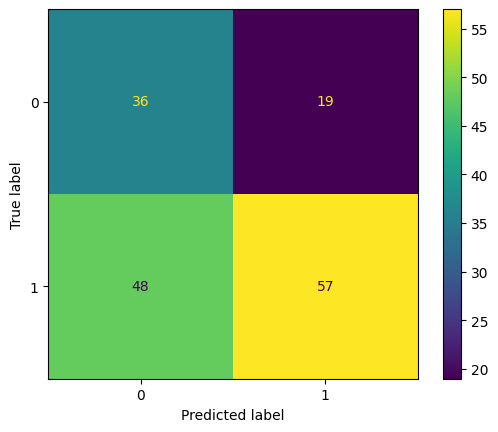

In [38]:
from sklearn.naive_bayes import GaussianNB
NB_pure_pipe =  GaussianNB()
NB_pure_pipe.fit(X_train, y_train)
y_pred_NB = NB_pure_pipe.predict(X_test)
#Modeling the accuracy on test data
print("Model Accuracy on Testing Data: ", NB_pure_pipe.score(X_test,y_test))
print("---CLASSIFICATION RESULTS ---")
print(classification_report(y_test, y_pred_NB))

ConfusionMatrixDisplay.from_estimator(NB_pure_pipe,X_test, y_test)
plt.show()

# Evaluation on The 3 models 

## Key findings:
SVM with RBF is the best performing model  for maximising recall as it captures non linear patterns that LR and RF missed. LR and RF performed similarly but we know  that there non-linear patterns which SVM found and NB performed worst confirming that there are indeed feature correlations as predicted.

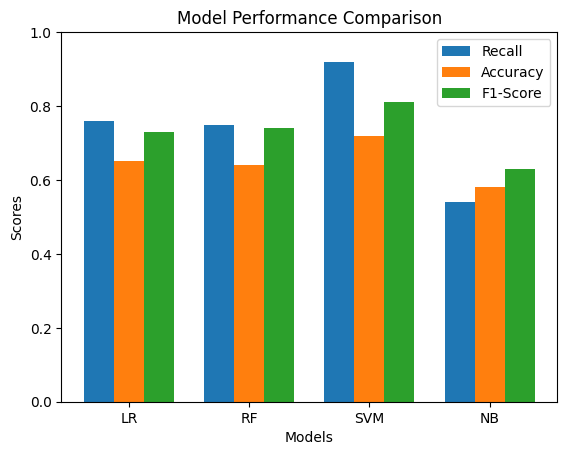

In [39]:

models = ['LR', 'RF', 'SVM', 'NB']
recall_scores = [0.76, 0.75, 0.92, 0.54]
accuracy_scores = [0.65, 0.64, 0.72, 0.58]
f1_scores = [0.73, 0.74, 0.81, 0.63]

#set bar position
x = np.arange(len(models))  # [0, 1, 2, 3]
width = 0.25  # width of each bar

# Create the bars
plt.bar(x - width, recall_scores, width, label='Recall')
plt.bar(x, accuracy_scores, width, label='Accuracy')
plt.bar(x + width, f1_scores, width, label='F1-Score')

plt.xlabel('Models')
plt.ylabel('Scores')
plt.title('Model Performance Comparison')
plt.xticks(x, models)  # Put model names on x-axis
plt.legend()
plt.ylim(0, 1)  # Scores range from 0 to 1
plt.show()

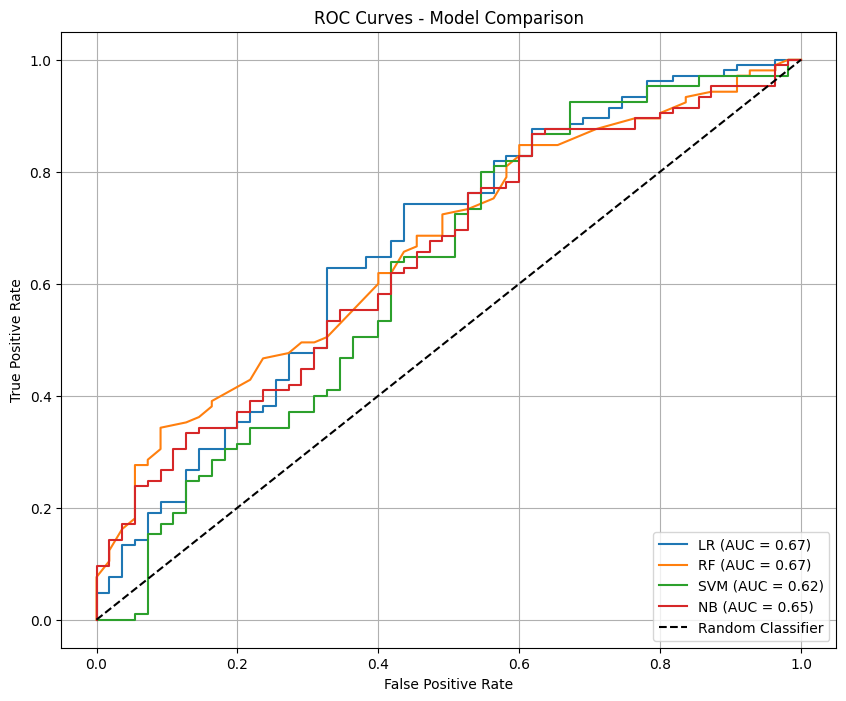

In [40]:
# Get the Probabilities for ROC Curve
# The model needs to guess the % chance, not just Yes/No
# Calculating ROC Metrics
# Getting probabilities for class 1 from each model
y_pred_proba_lr = pure_pipe.predict_proba(X_test)[:, 1]
y_pred_proba_rf = RF_pure_pipe.predict_proba(X_test)[:, 1]
y_pred_proba_svm = svm_pipe.predict_proba(X_test)[:, 1] 
y_pred_proba_nb = NB_pure_pipe.predict_proba(X_test)[:, 1]


fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_pred_proba_svm)
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_pred_proba_nb)

auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)
auc_svm = auc(fpr_svm, tpr_svm)
auc_nb = auc(fpr_nb, tpr_nb)

#Plot the Curve
plt.figure(figsize=(10, 8))

# Plot each model's ROC curve
plt.plot(fpr_lr, tpr_lr, label=f'LR (AUC = {auc_lr:.2f})')
plt.plot(fpr_rf, tpr_rf, label=f'RF (AUC = {auc_rf:.2f})')
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.2f})')
plt.plot(fpr_nb, tpr_nb, label=f'NB (AUC = {auc_nb:.2f})')

# Plot the diagonal line (random classifier)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# 6. HyperParameter Tuning
## Optimizing LR pure , LR balanced models and SVM

In [41]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
#Printing a list of knobs we will be using C, Penalty and the Solver
print(model.get_params())


{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [42]:
# Creating a menu of setting for computer to try 
#c_space = np.logspace(-5, 8, 15) #replacing [0.1,1,10,100] and the 15-point sweep with [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
param_grid_lr_pure = {
    'logisticregression__C':[0.1, 0.2, 0.4, 0.6, 0.8, 1.0],  #Testing the different strictness and complexity vs regularization levels with the orders of magnitude 
    'logisticregression__penalty':['l2'], #l1 deletes features which we have already done in feature selction stage so l2 is used to balance 
    'logisticregression__solver': ['liblinear', 'lbfgs'] #testing with liblinear great for small datasets and lbfgs standard default math engines 
    
}


In [43]:
from sklearn.model_selection import GridSearchCV

#Implementing the GridSearchCV


logreg_cv= GridSearchCV(
    estimator=pure_pipe, 
    param_grid=param_grid_lr_pure,
    scoring='f1_weighted', 
    cv=5, 
    verbose=1 # This prints a message so you know it's working!
)

logreg_cv.fit(X_train, y_train)

print("Tuned Logistic Regression Parameters: {}".format(logreg_cv.best_params_))
print("Best score is {}".format(logreg_cv.best_score_))

Fitting 5 folds for each of 12 candidates, totalling 60 fits


c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be remov

Tuned Logistic Regression Parameters: {'logisticregression__C': 0.8, 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'lbfgs'}
Best score is 0.5864940378866599


c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [44]:
# Tuning the model that Mohammed specially requested
weighted_logreg_cv = GridSearchCV(
    estimator=internal_balanced_pipe, 
    param_grid=param_grid_lr_pure, 
    scoring='f1_weighted', 
    cv=5, 
    verbose=1
)

weighted_logreg_cv.fit(X_train, y_train)

print("Tuned WEIGHTED Parameters: ", weighted_logreg_cv.best_params_)
print("Best WEIGHTED Score: ", weighted_logreg_cv.best_score_)

c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be remov

Fitting 5 folds for each of 12 candidates, totalling 60 fits


c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be remov

Tuned WEIGHTED Parameters:  {'logisticregression__C': 0.1, 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'liblinear'}
Best WEIGHTED Score:  0.6309322197744655


c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be remov

# Results
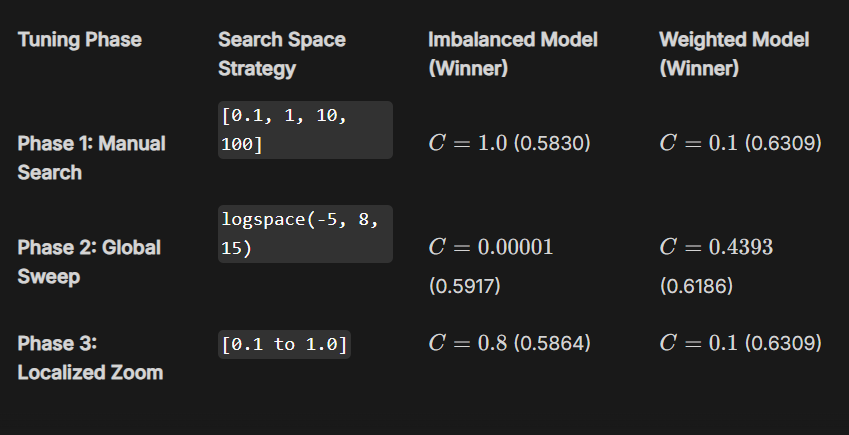

In [45]:
# getting the 'Best Estimator' (the winner) from search
final_weighted_lr = weighted_logreg_cv.best_estimator_

# Use the winner to guess the answers for X_test
y_pred_tuned = final_weighted_lr.predict(X_test)

# Print the classification report
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.44      0.67      0.53        55
           1       0.76      0.54      0.63       105

    accuracy                           0.59       160
   macro avg       0.60      0.61      0.58       160
weighted avg       0.65      0.59      0.60       160



# Analysis for LR tuning

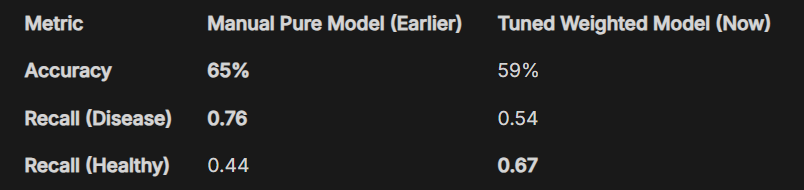

#### Comparing performance:
Hyperparamter tuning using a 15 point sweep showed a C value of 0.1 as the optimal regulirization strength. Even though the best score was 0.63, the final evaluation on the test set showed 59% accuracy, lower than the original pure baseline model at 65% but the same results as the internal weighted model untuned. This shows that the model reached a performance limit that linear models have; a straight line can only be so accurate. This verifies that the original settings on the manually balanced model were the best LR could do. Since medically, it is much safer to focus on recall for diseased patients to minimise false negatives the pure model outperfomes the weighted model tuned and untuned showing that the pure model is more 'safer' but at a high false positive rate for patients while the weighted model is more 'fair'at a high false negative rate.




In [46]:
#--------------------------SVM HYPERPARAMETER TUNING-------------------------------#

# defining the Safety Margin menu
c_sweep = np.logspace(0, 4, 10)      # From 1 to 10,000
gamma_sweep = np.logspace(-3, 1, 10)   # From 0.001 to 10
param_grid_svm = {
    'svc__C':c_sweep, #Phase 1 used [0.1, 1, 10, 100, 1000] =  61.1%, phase 2 = c_sweep = 61.0%
    'svc__gamma':gamma_sweep, #Phase 1 used [1, 0.1, 0.01, 0.001, 0.0001], phase 2 = gamma_sweep
    'svc__kernel': ['rbf'] # Using RBF for non-linear patterns
}

# 2. Setup the Search (Note: we use svm_pipe here)
svm_cv = GridSearchCV(
    estimator=svm_pipe, 
    param_grid=param_grid_svm, 
    scoring='f1_weighted', 
    cv=5, 
    verbose=1
)

# 3. Fit on your Training data
svm_cv.fit(X_train, y_train)

print("SVM Winning Parameters:", svm_cv.best_params_)
print("SVM Best Score:", svm_cv.best_score_)



Fitting 5 folds for each of 100 candidates, totalling 500 fits
SVM Winning Parameters: {'svc__C': np.float64(21.544346900318832), 'svc__gamma': np.float64(1.2915496650148828), 'svc__kernel': 'rbf'}
SVM Best Score: 0.6102299332758003


--- TUNED SVM: FINAL TEST RESULTS ---
              precision    recall  f1-score   support

           0       0.44      0.33      0.38        55
           1       0.69      0.78      0.73       105

    accuracy                           0.62       160
   macro avg       0.56      0.55      0.55       160
weighted avg       0.60      0.62      0.61       160



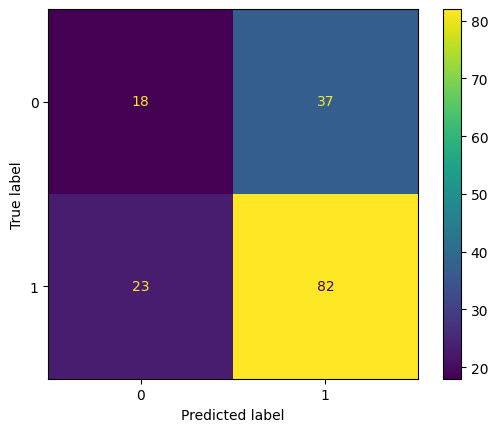

In [47]:
# 1. Grab the winner from the global search
final_tuned_svm = svm_cv.best_estimator_

# 2. Take the exam
y_pred_svm_tuned = final_tuned_svm.predict(X_test)

# 3. Print the report```
print("--- TUNED SVM: FINAL TEST RESULTS ---")
print(classification_report(y_test, y_pred_svm_tuned))

# 4. Matrix Display
ConfusionMatrixDisplay.from_estimator(final_tuned_svm, X_test, y_test)
plt.show()

## Refined SVM tuning

In [48]:
#--------------------------SVM HYPERPARAMETER REFINED TUNING-------------------------------#

# defining the Safety Margin menu
c_sweep = [0.1, 1, 10, 100, 1000]
gamma_sweep = [0.001, 0.01, 0.1, 0.001, 0.0001]
param_grid_svm_v2 = {
    'svc__C':c_sweep, #Phase 1 used [0.1, 1, 10, 100, 1000] =  0.65
    'svc__gamma':gamma_sweep, #Phase 1 used [1, 0.1, 0.01, 0.001, 0.0001], phase 2 = gamma_sweep
    'svc__kernel': ['linear', 'rbf', 'poly']# Adding Linear and Poly to prove RBF is best
}

# 2. Setup the Search (Note: we use svm_pipe here)
svm_cv_v2 = GridSearchCV(
    estimator=svm_pipe, 
    param_grid=param_grid_svm_v2, 
    scoring='f1_weighted', 
    cv=5, 
    verbose=1,
    n_jobs=-1
)

# 3. Fit on your Training data
svm_cv_v2.fit(X_train, y_train)

print("SVM Winning Parameters:", svm_cv_v2.best_params_)
print("SVM Best Score:", svm_cv_v2.best_score_)


Fitting 5 folds for each of 75 candidates, totalling 375 fits
SVM Winning Parameters: {'svc__C': 10, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
SVM Best Score: 0.5527264815593785


--- REFINED TUNED SVM: FINAL TEST RESULTS ---
              precision    recall  f1-score   support

           0       0.47      0.47      0.47        55
           1       0.72      0.72      0.72       105

    accuracy                           0.64       160
   macro avg       0.60      0.60      0.60       160
weighted avg       0.64      0.64      0.64       160



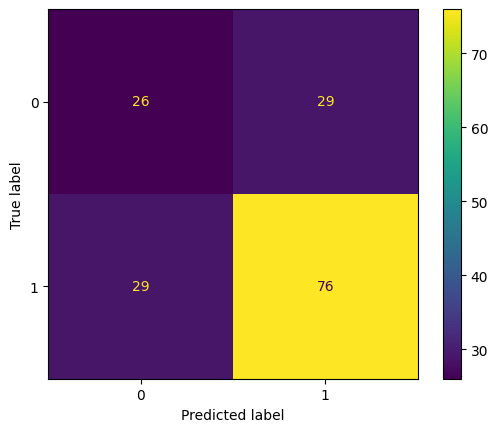

In [49]:
# 1. Grab the winner from the global search
final_tuned_svm_v2 = svm_cv_v2.best_estimator_

# 2. Take the exam
y_pred_svm_tuned_v2 = final_tuned_svm_v2.predict(X_test)

# 3. Print the report```
print("--- REFINED TUNED SVM: FINAL TEST RESULTS ---")
print(classification_report(y_test, y_pred_svm_tuned_v2))

# 4. Matrix Display
ConfusionMatrixDisplay.from_estimator(final_tuned_svm_v2, X_test, y_test)
plt.show()

# Analysis for SVM tuning

## Comparing performance
After trying to tune the SVM model The model seemed to have performed worse that the untuned model at a recall for disease of 0.78 vs 0.92, 0.81 for diseased f1 vs 0.73 and accuracy also reduced by 11% but perfomed better than the tuned LR models. Tuning for a balnced f1-score actually reduced clinical saftey so i have chosen to retain the baseline svm configurations for my ensamble. 

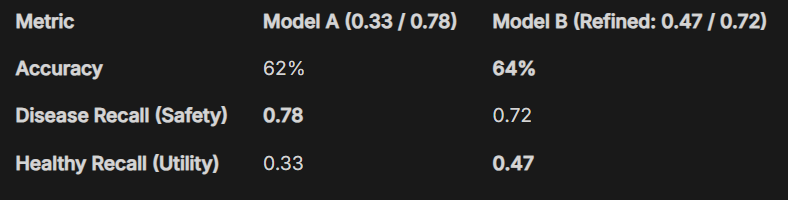


--- TUNED RANDOM FOREST: FINAL RESULTS ---
              precision    recall  f1-score   support

           0       0.55      0.44      0.48        55
           1       0.73      0.81      0.77       105

    accuracy                           0.68       160
   macro avg       0.64      0.62      0.63       160
weighted avg       0.67      0.68      0.67       160



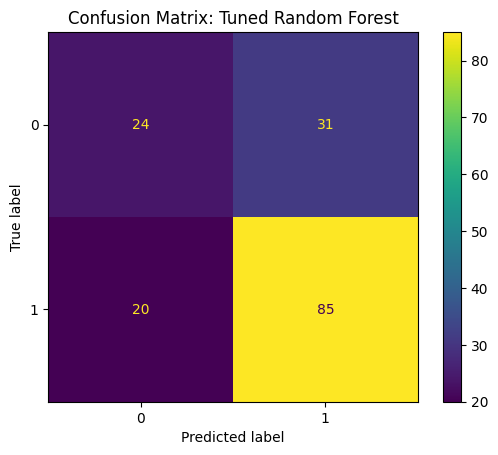

In [50]:
#--------------------------RF HYPERPARAMETER TUNING-------------------------------#
rf_tuned_pipeline = make_pipeline(RandomForestClassifier(random_state=42))

# Random Forest Optimization
param_grid_rf = {
    'randomforestclassifier__n_estimators': [50, 100, 200], # How many trees in the forest
    'randomforestclassifier__max_depth': [5, 10, 15, None], # How tall the trees grow
    'randomforestclassifier__min_samples_split': [2, 5, 10] # How much data needed to make a branch
}
# Performing grid search
rf_grid_search = GridSearchCV(estimator=rf_tuned_pipeline,
                           param_grid=param_grid_rf,
                           cv=5,
                           scoring='f1_weighted',)
rf_grid_search.fit(X_train, y_train)

#  Extract the specific 'Champion' Random Forest
final_rf_model = rf_grid_search.best_estimator_

#  Take the final exam
y_pred_rf_tuned = final_rf_model.predict(X_test)

print("--- TUNED RANDOM FOREST: FINAL RESULTS ---")
print(classification_report(y_test, y_pred_rf_tuned))

#  Display the Matrix for this specific winner
ConfusionMatrixDisplay.from_estimator(final_rf_model, X_test, y_test)
plt.title("Confusion Matrix: Tuned Random Forest")
plt.show()

## Refined tuned Random forest

--- REFINED RANDOM FOREST: FINAL RESULTS ---
              precision    recall  f1-score   support

           0       0.55      0.44      0.48        55
           1       0.73      0.81      0.77       105

    accuracy                           0.68       160
   macro avg       0.64      0.62      0.63       160
weighted avg       0.67      0.68      0.67       160



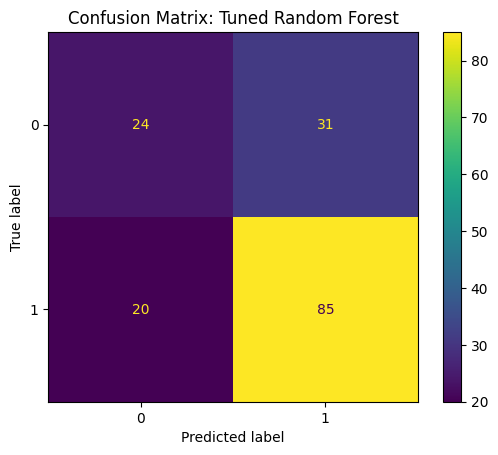

In [51]:
#--------------------------RF HYPERPARAMETER TUNING-------------------------------#
rf_tuned_pipeline_v2 = make_pipeline(RandomForestClassifier(random_state=42))

# Random Forest Optimization
param_grid_rf_refined = {
    'randomforestclassifier__n_estimators': [10, 25, 50, 75, 100, 125, 150, 175, 200], # How many trees in the forest
    'randomforestclassifier__max_depth': [5, 10, 15, None], # How tall the trees grow
    'randomforestclassifier__min_samples_split': [2, 5, 10] # How much data needed to make a branch
}
# Performing grid search
rf_grid_search = GridSearchCV(estimator=rf_tuned_pipeline,
                           param_grid=param_grid_rf_refined,
                           cv=5,
                           scoring='f1_weighted',)
rf_grid_search.fit(X_train, y_train)

#  Extract the specific 'Champion' Random Forest
final_rf_model_v2 = rf_grid_search.best_estimator_

#  Take the final exam
y_pred_rf_tuned_v2 = final_rf_model_v2.predict(X_test)

print("--- REFINED RANDOM FOREST: FINAL RESULTS ---")
print(classification_report(y_test, y_pred_rf_tuned_v2))

#  Display the Matrix for this specific winner
ConfusionMatrixDisplay.from_estimator(final_rf_model_v2, X_test, y_test)
plt.title("Confusion Matrix: Tuned Random Forest")
plt.show()

In [52]:
print("Winning Parameters:", rf_grid_search.best_params_)

Winning Parameters: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 200}


# Final Analysis on tuned models

The tuned RF performed better than the untuned rf model and was able to catch 6% more recall stroke cases at 0.81. It also performed better in precision for class 0 at 0.55 from 0.48 with fewer false alarms. However the healthy recall stayed the same at 0.44. This is because SVM and LR try to finds the optimal through the whole dataset whilst RF is a local model that caatch specific subgroups of patients. This model is the strongest non-linear model in the ensamble as it is safer than LR and more balanced than SVM.

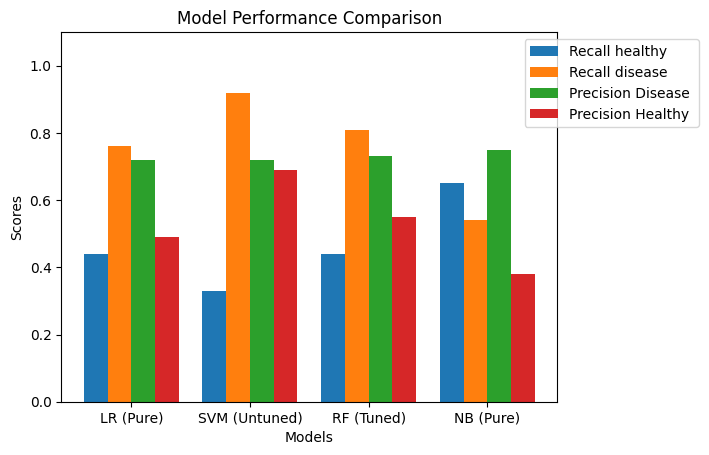

In [53]:
# Grouped Bar Chart Data

x = np.arange(4)
models = ['LR (Pure)', 'SVM (Untuned)', 'RF (Tuned)', 'NB (Pure)']
recall_0 = [0.44, 0.33, 0.44, 0.65]   # Healthy Safety
recall_1 = [0.76, 0.92, 0.81, 0.54]   # Disease Safety (Priority)
prec_1 = [0.72, 0.72, 0.73, 0.75]     # Disease Precision
prec_0 = [0.49, 0.69, 0.55, 0.38]     # Disease Precision
width = 0.2
#set bar position
x = np.arange(len(models))  # [0, 1, 2, 3]


# plot data in grouped manner of bar type
plt.bar(x-1.5*width, recall_0, width, label='Recall healthy')
plt.bar(x- 0.5*width, recall_1, width, label='Recall disease')
plt.bar(x + 0.5*width, prec_1, width, label='Precision Disease')
plt.bar(x+1.5*width, prec_0, width, label='Precision Healthy ')

for label in ax.containers:
    ax.bar_label(label)#adding number values to bar objects 
plt.xticks(x, models)
plt.title('Model Performance Comparison')
plt.xlabel("Models")
plt.ylabel("Scores")
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))
plt.ylim(0, 1.1)  # Scores range from 0 to 1

plt.show()



# 7. Ensamble Model Building

In [54]:
from sklearn.ensemble import VotingClassifier
#Defining chosen list for ensamble model
ens_models = [('SVM',svm_pipe),('RF',RF_pure_pipe),('LR',pure_pipe)]
#defining voting classifier with soft voting parameter to average percentages and confidence for transparency 
voting_model_eq = VotingClassifier(
    estimators= ens_models,
    voting = 'soft',
    weights=[1,1,1], # giving same weight for fairness
    n_jobs=-1, # trains models simultanuously for speed
    verbose=True,
    flatten_transform=True
)

In [55]:
voting_model_eq.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('SVM', ...), ('RF', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.","[1, 1, ...]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",-1
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",True
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'


In [56]:
ensemble_preds = voting_model_eq.predict(X_test)
print("Ensemble Jury has reached a verdict.")
print(classification_report(y_test, ensemble_preds))

Ensemble Jury has reached a verdict.
              precision    recall  f1-score   support

           0       0.53      0.31      0.39        55
           1       0.70      0.86      0.77       105

    accuracy                           0.67       160
   macro avg       0.62      0.58      0.58       160
weighted avg       0.64      0.67      0.64       160



# 7.2 Weighted Ensemble 

In [57]:
from sklearn.ensemble import VotingClassifier
#Defining chosen list for ensamble model
ens_models = [('SVM',svm_pipe),('RF',RF_pure_pipe),('LR',pure_pipe)]
#defining voting classifier with soft voting parameter to average percentages and confidence for transparency 
voting_model_svmweight = VotingClassifier(
    estimators= ens_models,
    voting = 'soft',
    weights=[2,1,1], # giving more weight to SVM
    n_jobs=-1, # trains models simultanuously for speed
    verbose=True,
    flatten_transform=True
)

voting_model_svmweight.fit(X_train, y_train)

weighted_preds = voting_model_svmweight.predict(X_test)
print("Ensemble Jury has reached a verdict.")
print(classification_report(y_test, weighted_preds))

Ensemble Jury has reached a verdict.
              precision    recall  f1-score   support

           0       0.61      0.20      0.30        55
           1       0.69      0.93      0.79       105

    accuracy                           0.68       160
   macro avg       0.65      0.57      0.55       160
weighted avg       0.66      0.68      0.62       160



In [58]:
from sklearn.ensemble import VotingClassifier
#Defining chosen list for ensamble model
ens_models = [('SVM',svm_pipe),('RF',RF_pure_pipe),('LR',pure_pipe)]
#defining voting classifier with soft voting parameter to average percentages and confidence for transparency 
voting_model_rflrweight = VotingClassifier(
    estimators= ens_models,
    voting = 'soft',
    weights=[1,2,2], # giving more weight to RF and LR 
    n_jobs=-1, # trains models simultanuously for speed
    verbose=True,
    flatten_transform=True
)

voting_model_rflrweight.fit(X_train, y_train)

levelheaded_preds = voting_model_rflrweight.predict(X_test)
print("Ensemble Jury has reached a verdict.")
print(classification_report(y_test, levelheaded_preds))

Ensemble Jury has reached a verdict.
              precision    recall  f1-score   support

           0       0.59      0.40      0.48        55
           1       0.73      0.86      0.79       105

    accuracy                           0.70       160
   macro avg       0.66      0.63      0.63       160
weighted avg       0.68      0.70      0.68       160



In [60]:
from sklearn.model_selection import cross_val_score


# K-Fold Cross Validation on Voting Ensemble
kfold_scores = cross_val_score(
    voting_model_rflrweight, 
    X_train, 
    y_train, 
    cv=10, 
    scoring='f1_weighted',
    n_jobs=-1
)

print("K-Fold CV Results (10 Fold):")
print(f"Individual Fold Scores: {kfold_scores}")
print(f"Mean F1 Score: {kfold_scores.mean():.4f}")
print(f"Standard Deviation: {kfold_scores.std():.4f}")

K-Fold CV Results (10 Fold):
Individual Fold Scores: [0.53081232 0.48888889 0.57407407 0.65925926 0.38020833 0.45341803
 0.59090909 0.49074074 0.48626374 0.67307692]
Mean F1 Score: 0.5328
Standard Deviation: 0.0873


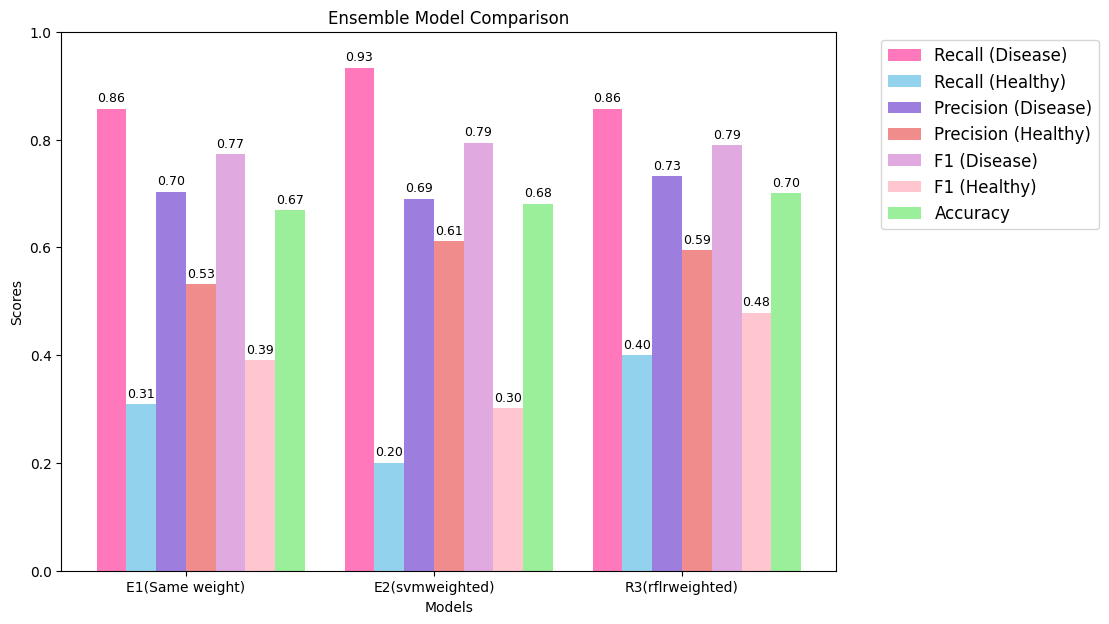

In [61]:

ens_m = [('E1(Same weight)',voting_model_eq),('E2(svmweighted)',voting_model_svmweight),('R3(rflrweighted)',voting_model_rflrweight)] #The tuples 
#loop through each score and save it as the variable names 
recall_disease = []    
recall_healthy = []    
f1_disease = []  
f1_healthy = [] 
prec_disease = []    
prec_healthy = []       
accuracy_scores = [] 
for ens in ens_m:
    name, model = ens
    result = model.predict(X_test)
    report = classification_report(y_test, result, output_dict=True)
    recall_disease.append(report['1']['recall'])
    recall_healthy.append(report['0']['recall'])
    f1_disease.append(report['1']['f1-score'])
    f1_healthy.append(report['0']['f1-score'])
    prec_disease.append(report['1']['precision'])
    prec_healthy.append(report['0']['precision'])
    accuracy_scores.append(report['accuracy'])

#set bar position

plt.figure(figsize=(10, 7))
x = np.arange(len(ens_m))  # [0, 1, 2, 3]
width = 0.12  # width of each bar

bar1 = plt.bar(x - 2.5*width, recall_disease, width, label='Recall (Disease)', color='hotpink', alpha=0.9)
bar2 = plt.bar(x - 1.5*width, recall_healthy, width, label='Recall (Healthy)', color='skyblue', alpha=0.9)
bar3 = plt.bar(x - 0.5*width, prec_disease, width, label='Precision (Disease)', color='mediumpurple', alpha=0.9)
bar4 = plt.bar(x + 0.5*width, prec_healthy, width, label='Precision (Healthy)', color='lightcoral', alpha=0.9)
bar5 = plt.bar(x + 1.5*width, f1_disease, width, label='F1 (Disease)', color='plum', alpha=0.9)
bar6 = plt.bar(x + 2.5*width, f1_healthy, width, label='F1 (Healthy)', color='pink', alpha=0.9)
bar7 = plt.bar(x + 3.5*width, accuracy_scores, width, label='Accuracy', color='lightgreen', alpha=0.9)

# Add value labels on top of each bar
for bar in [bar1, bar2, bar3, bar4, bar5, bar6, bar7]:
    plt.bar_label(bar, padding=3, fmt='%.2f', fontsize=9)


plt.xlabel('Models')
plt.ylabel('Scores')
plt.title('Ensemble Model Comparison')
plt.xticks(x, [name for name, _ in ens_m]) # Put model names on x-axis
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1), fontsize=12)
plt.ylim(0, 1)  # Scores range from 0 to 1
plt.show()

##### With an accuracy of 0.70 , a disease recall of 0.86 and a healthy recall of 0.40, this version is the best possible metrics for the voting ensemble model for all phases giving a balanced result; tested after trying different weights and ensemble methods. However for the safest model which gives more weight to the SVM has the highest recall for disease at 0.92 however its healthy recall at 0.11 brings down its performance.I deliberately combined models with different class-handling strategies such as balanced or imbalanced to observe if the diversity would lead to a more stable ensemble.

# Extra research

# Stacking method

In [62]:
from sklearn.ensemble import StackingClassifier
stacking = StackingClassifier(
    estimators = ens_models , 
    final_estimator = pure_pipe,
    cv = 5
)

stacking.fit(X_train , y_train)

y_stack_pred = stacking.predict(X_test)
print("Stacking Jury has reached a verdict.")
print(classification_report(y_test, y_stack_pred))


Stacking Jury has reached a verdict.
              precision    recall  f1-score   support

           0       0.47      0.33      0.39        55
           1       0.70      0.81      0.75       105

    accuracy                           0.64       160
   macro avg       0.59      0.57      0.57       160
weighted avg       0.62      0.64      0.62       160



# Bagging method

In [63]:
from sklearn.ensemble import BaggingClassifier
bagging = BaggingClassifier(
    estimator=model, 
    n_estimators=100,  # How many clones 
    max_samples=0.8,   # Each clone only sees 80% of the data
    bootstrap=True,    
    n_jobs=-1          
)


bagging.fit(X_train , y_train)
y_pred_bag = bagging.predict(X_test)
print("bagging Jury has reached a verdict.")
print(classification_report(y_test, y_pred_bag))

bagging Jury has reached a verdict.
              precision    recall  f1-score   support

           0       0.49      0.44      0.46        55
           1       0.72      0.76      0.74       105

    accuracy                           0.65       160
   macro avg       0.61      0.60      0.60       160
weighted avg       0.64      0.65      0.64       160



In [64]:
from sklearn.model_selection import cross_val_score

# K-Fold Cross Validation on Ensemble
kfold_scores = cross_val_score(
    voting_model_rflrweight, 
    X_train, 
    y_train, 
    cv=5,              # 5 folds
    scoring='f1_weighted',
    n_jobs=-1
)

print("--- K-FOLD CROSS VALIDATION RESULTS ---")
print(f"Individual Fold Scores: {kfold_scores}")
print(f"Mean F1 Score: {kfold_scores.mean():.4f}")
print(f"Standard Deviation: {kfold_scores.std():.4f}")

--- K-FOLD CROSS VALIDATION RESULTS ---
Individual Fold Scores: [0.53081232 0.54918033 0.47129333 0.5706044  0.59772727]
Mean F1 Score: 0.5439
Standard Deviation: 0.0426


SHAP analysis reveals that the top 3 features are Alkphos, TB and Age  which shows  that the shift from Age(V2) to sgpt(V3) indicates that the row deletions with patients with extreme sgpt values from phase 2 hid the importance of the sgpt forcing the model to rely on demographic signals instead of clinical markers.

Kfolds showed: F1 = 0.64 ± 0.04 — poor generalization from overfitting small, "clean" dataset and F1 = 0.55 ± 0.06(5-fold) - poor generalization from overfitting.

Note: you may need to restart the kernel to use updated packages.


c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
  0%|          | 0/50 [00:00<?, ?it/s]c:\Users\prisc\Desktop\CS3IP_Stroke\.venv\Lib\site-packages

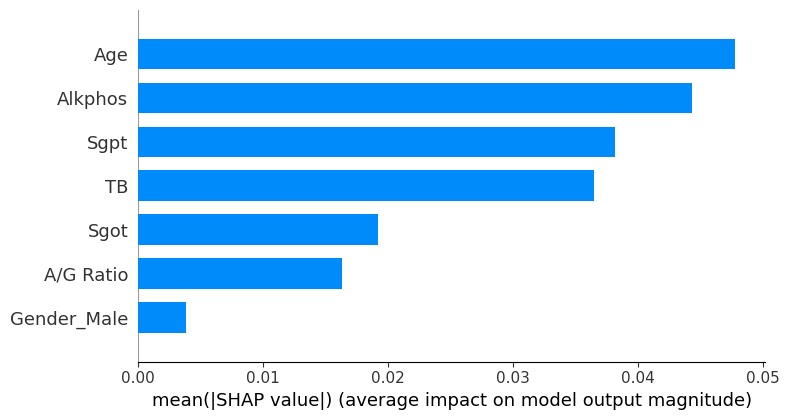

In [65]:
%pip install shap
import shap

# 1. Create a KernelExplainer for the ensemble
# KernelExplainer needs a prediction function and background data
def ensemble_predict(X):
    return voting_model_rflrweight.predict_proba(X)[:, 1]  # Probability of disease

# 2. Sample background data (SHAP needs this for comparison)
background = X_train.sample(100, random_state=42)  # 100 random samples

# 3. Create explainer
explainer = shap.KernelExplainer(ensemble_predict, background)

# 4. Calculate SHAP values for test set (sample for speed)
shap_values = explainer.shap_values(X_test.sample(50, random_state=42), nsamples=100)

# 5. Summary plot
shap.summary_plot(shap_values, X_test.sample(50, random_state=42), plot_type="bar")